# SurveyLens | Week 3 — Grouped Statistics & Machine Learning
**SkillMe Data Science Virtual Internship** · UCI Adult Census Income · continuation of Week 2

**Research question:** Do higher-income respondents work more hours per week, and can age, working hours, education, employment group and occupation predict income category?

We reuse the exact cleaned Week 2 CSV, compare group means and medians, perform a Welch t-test, then evaluate Logistic Regression and an optional Random Forest on the same held-out test set.

In [4]:
from google.colab import files
from pathlib import Path
import shutil

Path("data").mkdir(exist_ok=True)

uploaded = files.upload()

shutil.move("survey_clean.csv", "data/survey_clean.csv")

print("Dataset uploaded successfully!")

Saving survey_clean.csv to survey_clean.csv
Dataset uploaded successfully!


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from IPython.display import display, Markdown
import sklearn

ROOT = Path('.')
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
df = pd.read_csv(ROOT / 'data' / 'survey_clean.csv')
assert df.shape == (32561, 17)
assert not df.isna().any().any()
labels = ['<=50K', '>50K']
assert set(df.income) == set(labels)
print('Verified Week 2 dataset:', df.shape)
print('scikit-learn:', sklearn.__version__)
display(df.income.value_counts().to_frame('respondents'))

Verified Week 2 dataset: (32561, 17)
scikit-learn: 1.6.1


,respondents
income,
<=50K,24720
>50K,7841


## 1. Grouped comparison
Compare hours per week across income categories. The mean measures average hours; the median is less sensitive to extreme observations.

,count,mean,median,std
income,,,,
<=50K,24720,38.840,40.0,12.319
>50K,7841,45.473,40.0,11.013


Higher-income respondents work 6.63 more hours per week on average in this dataset.


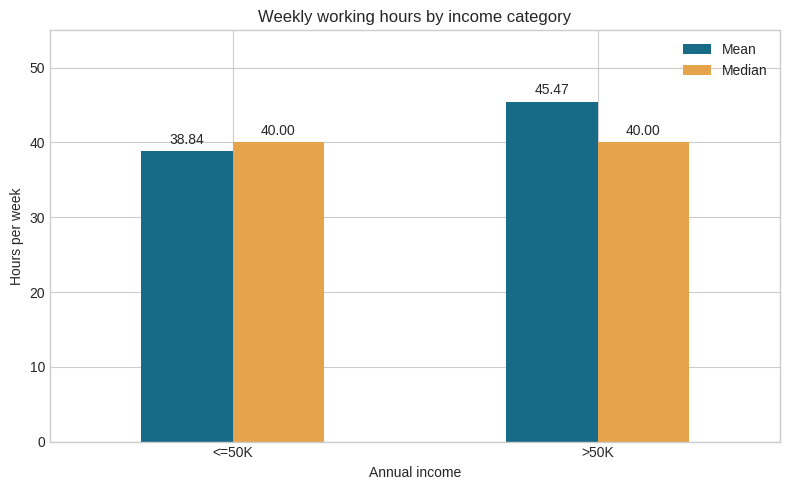

In [6]:
stats = df.groupby('income')['hours_per_week'].agg(['count','mean','median','std']).reindex(labels)
display(stats.round(3))
stats.to_csv(OUT / 'grouped_statistics.csv')
low = df.loc[df.income == labels[0], 'hours_per_week']
high = df.loc[df.income == labels[1], 'hours_per_week']
gap = high.mean() - low.mean()
print(f'Higher-income respondents work {gap:.2f} more hours per week on average in this dataset.')
fig, ax = plt.subplots(figsize=(8,5))
stats[['mean','median']].plot.bar(ax=ax, rot=0, color=['#176B87','#E5A34B'])
for container in ax.containers: ax.bar_label(container, fmt='%.2f', padding=3)
ax.set(title='Weekly working hours by income category', xlabel='Annual income', ylabel='Hours per week', ylim=(0,55))
ax.legend(['Mean','Median']); fig.tight_layout()
fig.savefig(OUT / '01_grouped_working_hours.png', dpi=180); plt.show()

## 2. Statistical significance and practical size
Welch's independent-samples t-test does not assume equal group variances. The null hypothesis is equal mean hours; use a two-sided significance level of 0.05. The mean difference and standardized effect size provide context beyond the p-value. This is an unweighted historical sample analysis, not a causal or population-representative estimate.

In [ ]:
test = ttest_ind(high, low, equal_var=False)
pooled_sd = np.sqrt(((len(high)-1)*high.var() + (len(low)-1)*low.var()) / (len(high)+len(low)-2))
d = gap / pooled_sd
p_text = f'{test.pvalue:.3e}' if test.pvalue > 0 else '< numerical precision'
conclusion = 'Reject equal means at alpha=0.05' if test.pvalue < 0.05 else 'Do not reject equal means at alpha=0.05'
print(f'Welch t = {test.statistic:.3f}; p = {p_text}')
print(f'Mean difference = {gap:.2f} hours; Cohen d = {d:.3f}')
print(conclusion)
pd.DataFrame([{'t':test.statistic,'p':test.pvalue,'mean_gap_hours':gap,'cohen_d':d,'conclusion':conclusion}]).to_csv(OUT/'significance_test.csv', index=False)

## 3. Prepare five features and split data
Target: `income`. Numeric features: `age`, `hours_per_week`. Categorical features: `education`, `workclass_group`, `occupation`. Stratification preserves the class proportions. Scaling and one-hot encoding are fitted only on the training partition through a pipeline to avoid leakage. Current scikit-learn automatically handles binary/multiclass logistic regression, so no deprecated `multi_class` argument is needed.

In [7]:
numeric = ['age','hours_per_week']
categorical = ['education','workclass_group','occupation']
X = df[numeric + categorical]
y = df['income']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
def make_preprocessor():
    return ColumnTransformer([('num', StandardScaler(), numeric), ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)])
print(f'Train: {len(X_train):,}; test: {len(X_test):,}')
display(pd.DataFrame({'train':y_train.value_counts(), 'test':y_test.value_counts()}))

Train: 26,048; test: 6,513


,train,test
income,,
<=50K,19775,4945
>50K,6273,1568


## 4. Train Logistic Regression and evaluate on unseen test data

              precision    recall  f1-score   support

       <=50K       0.82      0.94      0.88      4945
        >50K       0.65      0.37      0.47      1568

    accuracy                           0.80      6513
   macro avg       0.73      0.65      0.67      6513
weighted avg       0.78      0.80      0.78      6513

Accuracy: 79.92%; majority-class baseline: 75.93%


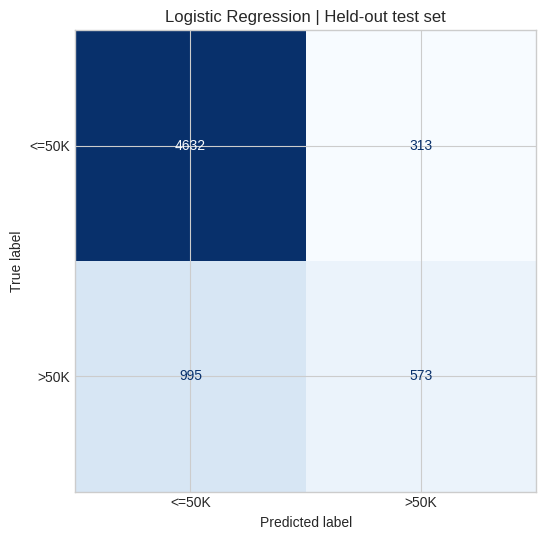

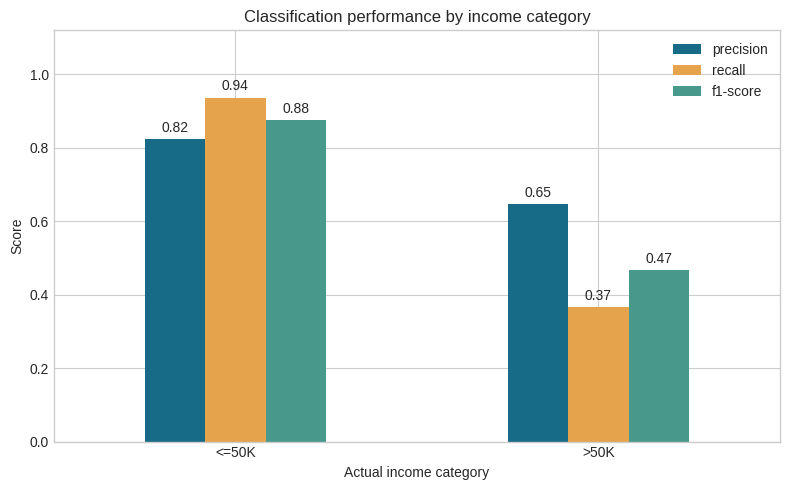

In [8]:
model = Pipeline([('preprocess',make_preprocessor()), ('classifier',LogisticRegression(max_iter=1000, random_state=42))])
model.fit(X_train,y_train)
pred = model.predict(X_test)
report = classification_report(y_test,pred,labels=labels,output_dict=True,zero_division=0)
report_df = pd.DataFrame(report).T
print(classification_report(y_test,pred,labels=labels,zero_division=0))
report_df.to_csv(OUT/'classification_report.csv')
accuracy = accuracy_score(y_test,pred)
baseline = (y_test == y_train.mode().iloc[0]).mean()
print(f'Accuracy: {accuracy:.2%}; majority-class baseline: {baseline:.2%}')
cm = confusion_matrix(y_test,pred,labels=labels)
assert cm.sum() == len(y_test)
pd.DataFrame(cm,index=labels,columns=labels).to_csv(OUT/'confusion_matrix.csv')
fig, ax = plt.subplots(figsize=(7,5.5))
ConfusionMatrixDisplay(cm,display_labels=labels).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
ax.set_title('Logistic Regression | Held-out test set'); fig.tight_layout()
fig.savefig(OUT/'02_confusion_matrix.png',dpi=180); plt.show()
fig, ax = plt.subplots(figsize=(8,5))
report_df.loc[labels,['precision','recall','f1-score']].plot.bar(ax=ax,rot=0,color=['#176B87','#E5A34B','#48998C'])
for container in ax.containers: ax.bar_label(container,fmt='%.2f',padding=3)
ax.set(ylim=(0,1.12),title='Classification performance by income category',xlabel='Actual income category',ylabel='Score')
fig.tight_layout(); fig.savefig(OUT/'03_classification_metrics.png',dpi=180); plt.show()

## 5. Interpretation — four sentences using actual model results

In [9]:
worst = min(labels,key=lambda label:report[label]['recall'])
i = labels.index(worst)
interpretation = (f'Logistic Regression correctly classified {cm.trace():,} of {len(y_test):,} test records ({accuracy:.2%} accuracy), versus {baseline:.2%} for the majority-class baseline. '
    f'The confusion matrix shows {cm[0,0]:,} correctly predicted <=50K records and {cm[1,1]:,} correctly predicted >50K records. '
    f'The model struggles most with {worst}, which has recall {report[worst]["recall"]:.2%} and F1 {report[worst]["f1-score"]:.3f}; {cm[i,1-i]:,} actual records in this category were assigned to the other category. '
    f'The two error counts ({cm[0,1]:,} lower-income records predicted higher and {cm[1,0]:,} higher-income records predicted lower) show why accuracy alone is insufficient.')
print(interpretation)
(OUT/'interpretation.txt').write_text(interpretation,encoding='utf-8')

Logistic Regression correctly classified 5,205 of 6,513 test records (79.92% accuracy), versus 75.93% for the majority-class baseline. The confusion matrix shows 4,632 correctly predicted <=50K records and 573 correctly predicted >50K records. The model struggles most with >50K, which has recall 36.54% and F1 0.467; 995 actual records in this category were assigned to the other category. The two error counts (313 lower-income records predicted higher and 995 higher-income records predicted lower) show why accuracy alone is insufficient.


542

## 6. Optional stretch goal — Random Forest on the same split
Compare macro F1 and recall for the rarer class, without tuning on the test set.

In [10]:
forest = Pipeline([('preprocess',make_preprocessor()),('classifier',RandomForestClassifier(n_estimators=150,min_samples_leaf=5,random_state=42,n_jobs=-1))])
forest.fit(X_train,y_train)
rf_pred = forest.predict(X_test)
rf_report = classification_report(y_test,rf_pred,labels=labels,output_dict=True,zero_division=0)
rare = y_train.value_counts().idxmin()
comparison = pd.DataFrame([
    {'model':'Logistic Regression','accuracy':accuracy,'macro_f1':f1_score(y_test,pred,average='macro'),'minority_recall':report[rare]['recall']},
    {'model':'Random Forest','accuracy':accuracy_score(y_test,rf_pred),'macro_f1':f1_score(y_test,rf_pred,average='macro'),'minority_recall':rf_report[rare]['recall']}]).set_index('model')
display(comparison.round(4))
comparison.to_csv(OUT/'model_comparison.csv')
best = comparison.minority_recall.idxmax()
print(f'On this split, {best} has the highest minority-class ({rare}) recall (ties favor the first row).')

,accuracy,macro_f1,minority_recall
model,,,
Logistic Regression,0.7992,0.6716,0.3654
Random Forest,0.8065,0.6841,0.3820


On this split, Random Forest has the highest minority-class (>50K) recall (ties favor the first row).


## 7. Limitations and reproducibility
The data are historical US census-derived records from 1994. Results are unweighted and observational; neither the t-test nor the classifier establishes causation. The income classes are imbalanced. Even without using race or sex as features, proxy effects and sampling bias may remain. This model is an educational exercise, not a tool for employment or lending decisions. A single split is not external validation.

Source: [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult). The bundled CSV is the actual cleaned output of Week 2.

In [12]:
import numpy as np
from scipy.stats import ttest_ind

test = ttest_ind(high, low, equal_var=False)
pooled_sd = np.sqrt(((len(high)-1)*high.var() + (len(low)-1)*low.var()) / (len(high)+len(low)-2))
d = gap / pooled_sd
p_text = f'{test.pvalue:.3e}' if test.pvalue > 0 else '< numerical precision'

assert all((OUT / f).exists() for f in [
    '01_grouped_working_hours.png',
    '02_confusion_matrix.png',
    '03_classification_metrics.png',
    'classification_report.csv',
    'interpretation.txt'
])

summary = f"""# Week 3 Analysis Results

- Total records: {len(df):,}
- Training records: {len(X_train):,}
- Testing records: {len(X_test):,}
- Lower-income average hours: {low.mean():.2f}
- Higher-income average hours: {high.mean():.2f}
- Difference in working hours: {gap:.2f}
- Welch t-statistic: {test.statistic:.3f}
- P-value: {p_text}
- Cohen's d: {d:.3f}
- Logistic Regression accuracy: {accuracy:.2%}
- Majority baseline: {baseline:.2%}

{interpretation}

Random Forest comparison:
{best} achieved the highest minority-class recall.
"""

(OUT / 'RESULTS.md').write_text(summary, encoding='utf-8')

print(summary)
print("Week 3 analysis completed successfully.")

# Week 3 Analysis Results

- Total records: 32,561
- Training records: 26,048
- Testing records: 6,513
- Lower-income average hours: 38.84
- Higher-income average hours: 45.47
- Difference in working hours: 6.63
- Welch t-statistic: 45.123
- P-value: < numerical precision
- Cohen's d: 0.552
- Logistic Regression accuracy: 79.92%
- Majority baseline: 75.93%

Logistic Regression correctly classified 5,205 of 6,513 test records (79.92% accuracy), versus 75.93% for the majority-class baseline. The confusion matrix shows 4,632 correctly predicted <=50K records and 573 correctly predicted >50K records. The model struggles most with >50K, which has recall 36.54% and F1 0.467; 995 actual records in this category were assigned to the other category. The two error counts (313 lower-income records predicted higher and 995 higher-income records predicted lower) show why accuracy alone is insufficient.

Random Forest comparison:
Random Forest achieved the highest minority-class recall.

Week 3 anal